In [ ]:
import re
import warnings
from pathlib import Path

import folium
import geopandas as gpd
import pandas as pd
import requests
from shapely.geometry import Polygon
from shapely.ops import unary_union

## Functions

Download the Biomass acquisition-plan KML files, read them and merge the area acquired up to a date.

In [ ]:
PLAN_URL = "https://earth.esa.int/eogateway/documents/d/earth-online/bio_oper_tom-gc1__majorcycle{cycle}"


def download_acquisition_plans(data_dir: str | Path, cycles: range = range(1, 8)) -> list[Path]:
    """Download the Biomass TOM acquisition-plan KML files from ESA Earth Online.

    Files already in ``data_dir`` are not downloaded again.

    Parameters
    ----------
    data_dir : str or Path
        Target folder, created if missing.
    cycles : range, optional
        Major cycles to download (1 to 7).

    Returns
    -------
    list of Path
        The KML files, one per major cycle.
    """
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    paths = []
    for cycle in cycles:
        existing = list(data_dir.glob(f"BIO_OPER_TOM-GC1__MajorCycle{cycle}*.kml"))
        if existing:
            paths.append(existing[0])
            continue
        response = requests.get(PLAN_URL.format(cycle=cycle), headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
        response.raise_for_status()
        name = re.search(r'filename="(.*?)"', response.headers["content-disposition"]).group(1)
        (data_dir / name).write_bytes(response.content)
        paths.append(data_dir / name)
    return paths


def read_acquisition_plan(path: str | Path) -> gpd.GeoDataFrame:
    """Read a Biomass acquisition-plan KML into a GeoDataFrame.

    The KML puts a bare LinearRing inside each Placemark, which GDAL cannot parse,
    so the file is parsed as text.

    Parameters
    ----------
    path : str or Path
        KML file, e.g. ``BIO_OPER_TOM-GC1__MajorCycle1.kml``.

    Returns
    -------
    gpd.GeoDataFrame
        One row per datatake with the KML attributes, ``begin`` and ``end`` as datetimes,
        and the footprint as a Polygon (EPSG:4326, lon/lat in degrees).
    """
    text = Path(path).read_text(encoding="utf-8")
    rows = []
    for placemark in re.findall(r"<Placemark>.*?</Placemark>", text, re.DOTALL):
        coords = re.search(r"<coordinates>(.*?)</coordinates>", placemark, re.DOTALL).group(1).split()
        row = dict(re.findall(r'<Data name="(.*?)">\s*<value>(.*?)</value>', placemark, re.DOTALL))
        row["begin"], row["end"] = re.search(r"<begin>(.*?)</begin>\s*<end>(.*?)</end>", placemark, re.DOTALL).groups()
        row["geometry"] = Polygon([tuple(map(float, c.split(",")[:2])) for c in coords])
        rows.append(row)
    plan = gpd.GeoDataFrame(rows, crs="EPSG:4326")
    plan[["begin", "end", "Start Time", "Stop Time"]] = plan[["begin", "end", "Start Time", "Stop Time"]].apply(
        pd.to_datetime
    )
    return plan


def read_acquisition_plans(paths: list[str | Path]) -> gpd.GeoDataFrame:
    """Read several acquisition-plan KML files into one GeoDataFrame.

    Parameters
    ----------
    paths : list of str or Path
        KML files, e.g. the 7 major cycles.

    Returns
    -------
    gpd.GeoDataFrame
        All datatakes of all files, see `read_acquisition_plan`.
    """
    return pd.concat([read_acquisition_plan(p) for p in paths], ignore_index=True)


def merge_acquired_area(
    plan: gpd.GeoDataFrame, until: str | pd.Timestamp, out_path: str | Path | None = None
) -> Polygon:
    """Merge the footprints of all datatakes that stopped before a date.

    Warns if the plan ends before ``until``, i.e. the area is not complete up to that date.

    Parameters
    ----------
    plan : gpd.GeoDataFrame
        Acquisition plan with ``Stop Time`` and ``geometry`` columns.
    until : str or pd.Timestamp
        Threshold date (UTC), e.g. ``"2026-09-30"``. Datatakes with ``Stop Time`` before it are kept.
    out_path : str or Path, optional
        If given, the merged area is saved there as GeoJSON (EPSG:4326), e.g. ``data/acquired_area.geojson``.

    Returns
    -------
    shapely.geometry.Polygon or shapely.geometry.MultiPolygon
        Union of the selected footprints (lon/lat, degrees).
    """
    until = pd.Timestamp(until)
    last_stop = plan["Stop Time"].max()
    if last_stop < until:
        warnings.warn(f"Plan ends at {last_stop}, before {until}: area is not covered up to the threshold.")
    area = unary_union(plan.loc[plan["Stop Time"] < until, "geometry"].tolist())
    if out_path is not None:
        gpd.GeoSeries([area], crs="EPSG:4326").to_file(out_path, driver="GeoJSON")
    return area

## Area acquired until 2026-09-30

In [2]:

kml_files = download_acquisition_plans("data")
print(len(kml_files), "files")

7 files


In [3]:
plan = read_acquisition_plans(kml_files)
print(plan["Stop Time"].min(), plan["Stop Time"].max())

2025-11-21 01:17:14 2027-04-08 23:44:56


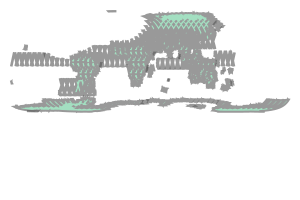

In [ ]:
acquired_area = merge_acquired_area(plan, until="2026-09-30", out_path="data/acquired_area_until_2026-09-30.geojson")

### Map of the acquired area

In [5]:

m = folium.Map(location=[0, 0], zoom_start=2)
folium.GeoJson(acquired_area.__geo_interface__, name="Acquired area").add_to(m)
folium.LayerControl().add_to(m)
m